# Qiskit Fall Fest 2026 – Challenge 2: Make the Quantum Coin Biased

**Goal:** Build a 1-qubit circuit (≤ 4 gates before measurement, 100 shots) whose outcomes 0 and 1 are **not** equally likely.

**Key idea:** The `RY(θ)` gate rotates the qubit about the Y-axis of the Bloch sphere:

$$RY(\theta)|0\rangle = \cos\tfrac{\theta}{2}|0\rangle + \sin\tfrac{\theta}{2}|1\rangle$$

so by the Born rule

$$P(0)=\cos^2\tfrac{\theta}{2},\qquad P(1)=\sin^2\tfrac{\theta}{2}.$$

Choosing θ lets us dial in any bias we like. (θ = π/2 gives the fair, Hadamard-like coin.)

In [1]:
# !pip install qiskit qiskit-aer matplotlib pylatexenc   # uncomment if needed
import numpy as np
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

SHOTS = 100
sim = AerSimulator()

def biased_coin(theta):
    """1 qubit, starts in |0>, one RY gate, then measure."""
    qc = QuantumCircuit(1, 1)
    qc.ry(theta, 0)          # 1 gate (limit is 4)
    qc.measure(0, 0)
    return qc

def run(qc, shots=SHOTS):
    return sim.run(qc, shots=shots).result().get_counts()

def predicted(theta):
    return np.cos(theta/2)**2, np.sin(theta/2)**2

## 1. Main circuit – the coin favours **0**

We use `RY(π/3)`:  P(0) = cos²(π/6) = **0.75**, P(1) = sin²(π/6) = **0.25**.

### Prediction (before running)
- **0** will occur more often.
- Expected ≈ **75 %** zeros (~75 of 100) and ≈ **25 %** ones (~25 of 100).
- If I change the gate angle, the percentages change; with θ > π/2 the bias flips toward 1.

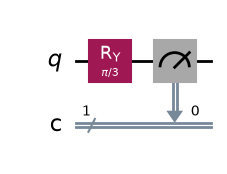

Predicted: P(0)=0.75, P(1)=0.25
Measured counts (100 shots): {'0': 81, '1': 19}


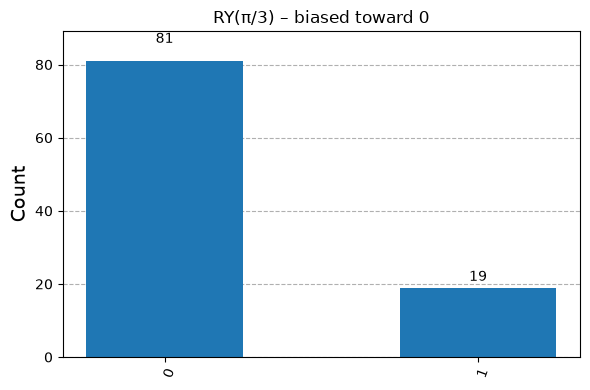

In [2]:
theta_main = np.pi/3
qc_main = biased_coin(theta_main)
display(qc_main.draw(output='mpl'))   # use print(qc_main.draw()) if mpl drawing is unavailable

p0, p1 = predicted(theta_main)
print(f"Predicted: P(0)={p0:.2f}, P(1)={p1:.2f}")

counts_main = run(qc_main)
print("Measured counts (100 shots):", dict(sorted(counts_main.items())))
plot_histogram(counts_main, title="RY(π/3) – biased toward 0", figsize=(6,4))

## 2. Bonus – two circuits: one favouring 0, one favouring 1

| Circuit | Gate | Predicted P(0) | Predicted P(1) |
|---|---|---|---|
| A | `RY(π/3)`  | 0.75 | 0.25 |
| B | `RY(2π/3)` | 0.25 | 0.75 |

Circuit B rotates the qubit past the equator of the Bloch sphere, so it ends up closer to |1⟩.

Circuit A (favours 0)


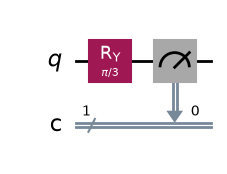

Circuit B (favours 1)


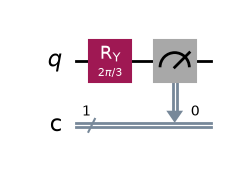

A: {'0': 73, '1': 27}  predicted [np.float64(0.75), np.float64(0.25)]
B: {'0': 18, '1': 82}  predicted [np.float64(0.25), np.float64(0.75)]


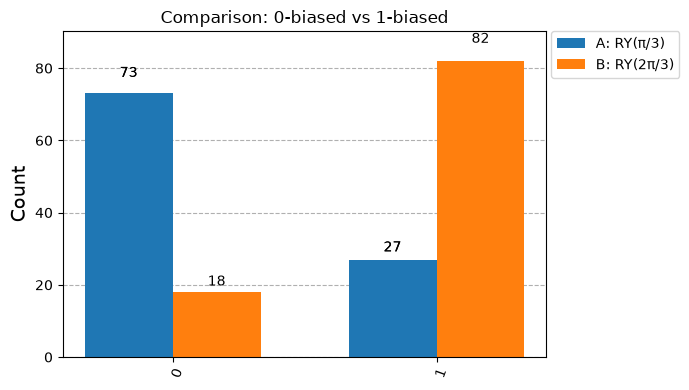

In [3]:
theta_A, theta_B = np.pi/3, 2*np.pi/3
qc_A, qc_B = biased_coin(theta_A), biased_coin(theta_B)

print("Circuit A (favours 0)"); display(qc_A.draw(output='mpl'))
print("Circuit B (favours 1)"); display(qc_B.draw(output='mpl'))

counts_A, counts_B = run(qc_A), run(qc_B)
print("A:", dict(sorted(counts_A.items())), " predicted", [round(x,2) for x in predicted(theta_A)])
print("B:", dict(sorted(counts_B.items())), " predicted", [round(x,2) for x in predicted(theta_B)])

plot_histogram([counts_A, counts_B], legend=['A: RY(π/3)', 'B: RY(2π/3)'],
               title="Comparison: 0-biased vs 1-biased", figsize=(7,4))

## 3. Different degrees of bias

Sweeping θ gives many biases. With only 100 shots, results fluctuate a few counts around the prediction (statistical noise, roughly ±4–5).

Gate       pred P(0) pred P(1)    #0    #1
RY(π/6)         0.93      0.07    93     7
RY(π/3)         0.75      0.25    72    28
RY(π/2)         0.50      0.50    53    47
RY(2π/3)        0.25      0.75    22    78
RY(5π/6)        0.07      0.93     6    94


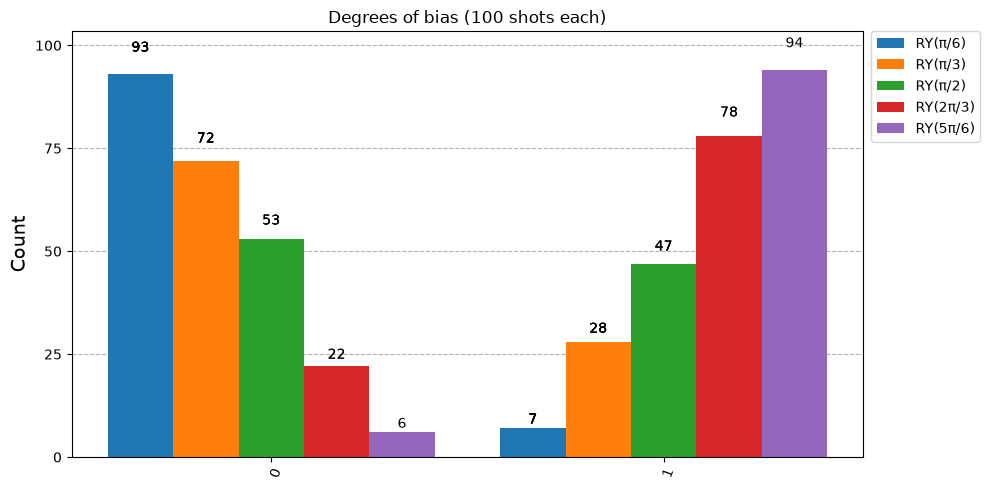

In [4]:
angles = {
    "RY(π/6)":  np.pi/6,    # P(1) ≈ 0.07
    "RY(π/3)":  np.pi/3,    # P(1) = 0.25
    "RY(π/2)":  np.pi/2,    # P(1) = 0.50  (fair coin)
    "RY(2π/3)": 2*np.pi/3,  # P(1) = 0.75
    "RY(5π/6)": 5*np.pi/6,  # P(1) ≈ 0.93
}

all_counts, labels = [], []
print(f"{'Gate':<10}{'pred P(0)':>10}{'pred P(1)':>10}{'#0':>6}{'#1':>6}")
for name, th in angles.items():
    c = run(biased_coin(th))
    p0, p1 = predicted(th)
    print(f"{name:<10}{p0:>10.2f}{p1:>10.2f}{c.get('0',0):>6}{c.get('1',0):>6}")
    all_counts.append(c); labels.append(name)

plot_histogram(all_counts, legend=labels, title="Degrees of bias (100 shots each)", figsize=(10,5))

## 4. Using several gates (still ≤ 4)

Rotations about the same axis add up: `RY(a)` followed by `RY(b)` equals `RY(a+b)`. Below, three gates before measurement give a total angle of π/6 + π/6 + π/3 = 2π/3, so P(1) = 0.75.

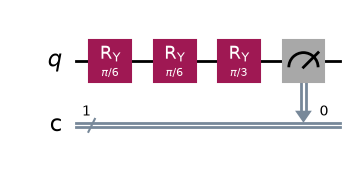

{'1': 70, '0': 30} (predicted P(1) = 0.75)


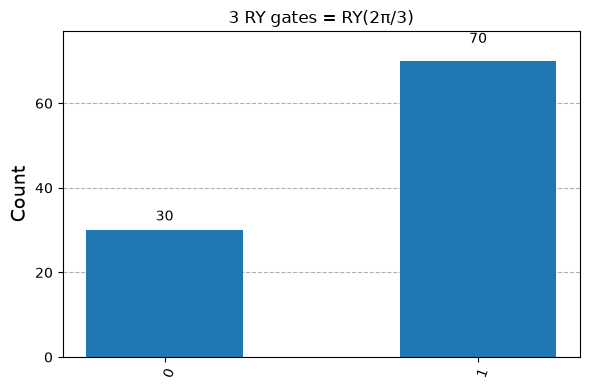

In [5]:
qc_multi = QuantumCircuit(1, 1)
qc_multi.ry(np.pi/6, 0)
qc_multi.ry(np.pi/6, 0)   # total so far = π/3   -> P(1) = 0.25
qc_multi.ry(np.pi/3, 0)   # total = 2π/3         -> P(1) = 0.75
qc_multi.measure(0, 0)
display(qc_multi.draw(output='mpl'))
counts_multi = run(qc_multi)
print(counts_multi, "(predicted P(1) = 0.75)")
plot_histogram(counts_multi, title="3 RY gates = RY(2π/3)", figsize=(6,4))

## 5. Explanation: how the gates changed the distribution

A fresh qubit is in |0⟩, so measuring it gives 0 every time. A Hadamard gate rotates the state to the equator of the Bloch sphere, giving 50/50. The `RY(θ)` gate instead lets us choose *how far* to rotate: the state becomes cos(θ/2)|0⟩ + sin(θ/2)|1⟩, so the probabilities are cos²(θ/2) and sin²(θ/2). A small θ keeps the qubit near |0⟩ (mostly 0s); θ = π/2 gives a fair coin; a larger θ pushes it toward |1⟩ (mostly 1s); θ = π flips it fully. The measured counts for 100 shots land near these predictions, with small random deviations due to finite sampling.

## Challenge Question

**How can quantum gates change the probability of obtaining 0 or 1 when a qubit is measured?**

A qubit's state is α|0⟩ + β|1⟩, and measurement returns 0 with probability |α|² and 1 with probability |β|² (the Born rule). Quantum gates are unitary operations that rotate the state vector on the Bloch sphere, which changes the amplitudes α and β. A state near the north pole gives mostly 0; near the south pole mostly 1; on the equator (e.g. after a Hadamard) an equal 50/50 mix. Gates such as `RY(θ)`, or a sequence of gates, rotate the state by a chosen angle, so the squared amplitudes, and therefore the measurement probabilities, can be tuned to any value between 0 and 1. The gates set the probabilities *before* measurement; the measurement itself then samples one outcome from that distribution.